In [1]:
import torch
import numpy as np
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import torchvision
import tqdm
import glob
from PIL import Image
import seaborn as sns
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

import sys
sys.path.append('../../vision')

import datasets
import training_loop
import losses
import models
import optimizers

if torch.cuda.is_available():
    device = torch.device('cuda:1')
else:
    device = torch.device('cpu')
print(device)

cuda:1


In [2]:
s3d_or_vit = 'vit'
# s3d_or_vit = 's3d'

In [96]:
labels = pd.read_csv("../../labels/semi_cleaned_labels_3_features_2024-10-21.csv")
labels = labels.drop(columns=['MRN','SURGERY_DATE'])

new_labels = labels.replace('nan', np.nan)
new_labels = new_labels.replace('nc', np.nan)

# drop nans:
new_labels.dropna(inplace=True) # needs to happen before sorting into pre and post

new_labels_pre = new_labels[['ACC_NUM','LVEF_pre','RVSF_pre','TR_pre']]
new_labels_pre.columns = ['ACC_NUM','LVEF','RVSF','TR']
new_labels_pre['prepost'] = 0

new_labels_post = new_labels[['ACC_NUM','LVEF_post','RVSF_post','TR_post']]
new_labels_post.columns = ['ACC_NUM','LVEF','RVSF','TR']
new_labels_post['prepost'] = 1

new_labels = pd.concat([new_labels_pre, new_labels_post])
new_labels.reset_index(drop=True, inplace=True)

new_labels['LVEF'] = new_labels['LVEF'].astype(float)/100
new_labels['RVSF'] = new_labels['RVSF'].astype(float)/6
new_labels['TR'] = new_labels['TR'].astype(float)/7

ground_truths = pd.read_csv("../../labels/500_reports_groundtruth.csv")['ACC_NUM']

# drop nans:
new_labels.dropna(inplace=True)

ground_truths = list(ground_truths.astype(float))

training_labels = new_labels.drop(new_labels[new_labels['ACC_NUM'].isin(ground_truths)].index)
evaluation_labels = new_labels.drop(new_labels[~new_labels['ACC_NUM'].isin(ground_truths)].index) # not quite correct, but probably good enough until we clean the gt dataset

print(len(training_labels), len(evaluation_labels))

11120 842


/tmp/ipykernel_1502971/1912813610.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_labels_pre['prepost'] = 0
/tmp/ipykernel_1502971/1912813610.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_labels_post['prepost'] = 1


In [97]:
view_prediction_csvs = glob.glob("../../labels/view_predictions/cycle_*/predictions_all_cycle_*.csv", recursive=True)
predictions = []
for cycle_preds in view_prediction_csvs:
    cycle = pd.read_csv(cycle_preds)
    predictions.append(cycle.loc[cycle['prediction'].isin([3,4,5,6,7,8,9])]) # If filtering by view - currently all 2,4,5 chamber with/without color
    predictions.append(cycle) # If not filtering by view

all_cycles = pd.concat(predictions)
all_cycles = all_cycles.reset_index()
val_cycles = all_cycles.sample(frac=0.01, random_state=0)
train_cycles = all_cycles.drop(val_cycles.index)

val_cycles = val_cycles.reset_index()
train_cycles = train_cycles.reset_index()

In [98]:
print(len(train_cycles))
removals = []
for i in tqdm.tqdm(range(len(train_cycles['clip_path']))):
    try:
        if int(os.path.basename(os.path.split(train_cycles['clip_path'].iloc[i])[0])) not in list(training_labels['ACC_NUM']):
        # if int(os.path.basename(os.path.split(train_cycles['clip_path'].iloc[i])[0])) in ground_truths:
            removals.append(i)
    except:
        removals.append(i)
train_cycles = train_cycles.drop(removals)
print(len(train_cycles))

print(len(val_cycles))
removals = []
for i in tqdm.tqdm(range(len(val_cycles['clip_path']))):
    try:
        if int(os.path.basename(os.path.split(val_cycles['clip_path'].iloc[i])[0])) not in list(training_labels['ACC_NUM']):
        # if int(os.path.basename(os.path.split(val_cycles['clip_path'].iloc[i])[0])) in ground_truths:
            removals.append(i)
    except:
        removals.append(i)
        
val_cycles = val_cycles.drop(removals)
print(len(val_cycles))
# train_cycles = train_cycles.reset_index(drop=True)
val_cycles = val_cycles.reset_index(drop=True)

756462


100%|██████████| 756462/756462 [05:23<00:00, 2335.78it/s]


607123
7641


100%|██████████| 7641/7641 [00:03<00:00, 2269.63it/s]

6099


In [99]:
train_clips = list(train_cycles['clip_path'])
val_clips = list(val_cycles['clip_path'])

# train_clips = ['/data/deep_tee/' + clip[8:] for clip in train_clips]
# val_clips = ['/data/deep_tee/' + clip[8:] for clip in val_clips]

In [100]:
prepost_pred = pd.read_csv('/home/trevor/repos/deep_TEE/labels/preop_postop_prediction.csv')
acc_nums = [prepost_pred['clip_path'][i].split('/')[0] if type(prepost_pred['clip_path'][i]) is str else '' for i in range(len(prepost_pred['clip_path']))]
dcm_nums = [prepost_pred['clip_path'][i].split('/')[-1] if type(prepost_pred['clip_path'][i]) is str else ''  for i in range(len(prepost_pred['clip_path']))]
prepost_pred['ACC_NUM'] = acc_nums
prepost_pred['DCM_NUM'] = dcm_nums

In [101]:
if s3d_or_vit == 's3d':
    train_transforms = datasets.TransformsComposed('train', size=(224,224))
    valtest_transforms = datasets.TransformsComposed('valtest', size=(224,224))
elif s3d_or_vit == 'vit':
    train_transforms = datasets.TransformsComposed('train', size=(128,128))
    valtest_transforms = datasets.TransformsComposed('valtest', size=(128,128))

In [102]:
features = ['LVEF','RVSF','TR']

In [103]:
train_dataset = datasets.VideoDataset(clip_paths=train_clips, labels_df=training_labels, features=features, time_df=prepost_pred, transform=train_transforms, duration=32, skip=2)
test_dataset = datasets.VideoDataset(clip_paths=val_clips, labels_df=training_labels,  features=features, time_df=prepost_pred, transform=valtest_transforms, duration=32, skip=2)

In [116]:
model = models.fetch_vit_model(
        spatial_size = (128,128),
        temporal_size = 32,
        residual_pool = False,
        residual_with_cls_embed = False,
        stochastic_depth_prob = 0.0,
        rel_pos_embed = True,
        proj_after_attn = True,
        num_classes = 3,
    ).to(device)


# model = models.fetch_s3d_model(
#     num_classes = 3,
#     dropout = 0,
# ).to(device)

# model = models.fetch_resnet_model(
#     num_classes = 1,
# ).to(device)

In [117]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.00001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0,)
# optimizer = optimizers.AnnealedAdam(model.parameters(), lr=1e-5, betas=(0.9, 0.999), eps=1e-8, weight_decay=0, amsgrad=False, t_up = 1<<12, t_down = 1<<18)

In [118]:
loss_fn = losses.MaskedLoss()

In [119]:
training_loop.simple_training_loop(
    run_dir             = '../experiments/test_vit_128_32_1_0_3feature_nchamberfilter_test2',  # Output directory.
    dataset             = train_dataset,                # Options for training set.
    validation_dataset  = test_dataset,                 # Options for training set.
    network             = model,                        # Options for model and preconditioning.
    loss                = loss_fn,                      # Options for loss function.
    optimizer           = optimizer,                    # Options for optimizer.
    seed                = 0,                            # Global random seed.
    batch_size          = 32,                           # Total batch size for one training iteration.
    num_workers         = 16,                            # Number of data loading workers.
    total_kimg          = 5000,                          # Training duration, measured in thousands of training images.
    kimg_per_tick       = 10,                           # How often to log training and validation stats.
    kimg_per_save       = 50,                           # How often to save the training state.
    device              = torch.device('cuda'),
)

Loading dataset...
Constructing network...
Setting up optimizer...
Setting up logs...
Training for 5000 kimg...



OutOfMemoryError: CUDA out of memory. Tried to allocate 1024.00 MiB (GPU 0; 47.38 GiB total capacity; 45.91 GiB already allocated; 323.06 MiB free; 46.54 GiB reserved in total by PyTorch) If reserved memory is >> allocated memory try setting max_split_size_mb to avoid fragmentation.  See documentation for Memory Management and PYTORCH_CUDA_ALLOC_CONF

# Evaluation

In [12]:
import json
# log = json.load(open('/home/trevor/repos/deep_TEE/tasks/experiments/test_s3d_224_32_1_0_3feature_nchamberfilter_test1/log.json', 'r'))

# log = json.load(open('/home/trevor/repos/deep_TEE/tasks/experiments/test_s3d_224_32_1_0_3feature_nchamberfilter_test2/log.json', 'r'))
log = json.load(open('/home/trevor/repos/deep_TEE/tasks/experiments/test_vit_128_32_1_0_3feature_nchamberfilter_test2/log.json', 'r'))

(0.0001, 0.0007)

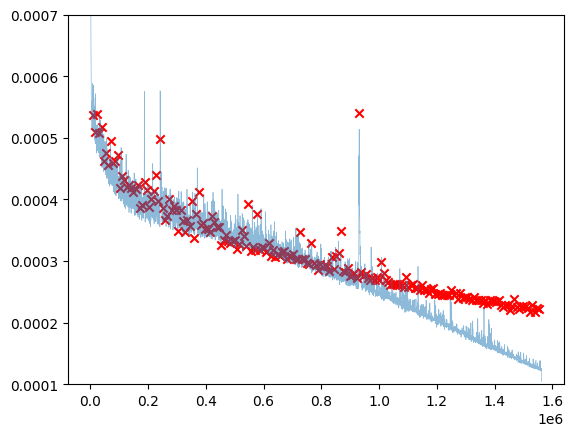

In [13]:
plt.plot(np.array(log['tick']), log['loss'], linewidth=0.5, alpha=0.5)
plt.scatter([log['tick'][i] for i,j in enumerate(log['valloss']) if not np.isnan(j)], [i for i in log['valloss'] if not np.isnan(i)], c='r', marker='x')
plt.gca().set_ylim([0.0001,0.0007])
# plt.gca().set_yscale('log')

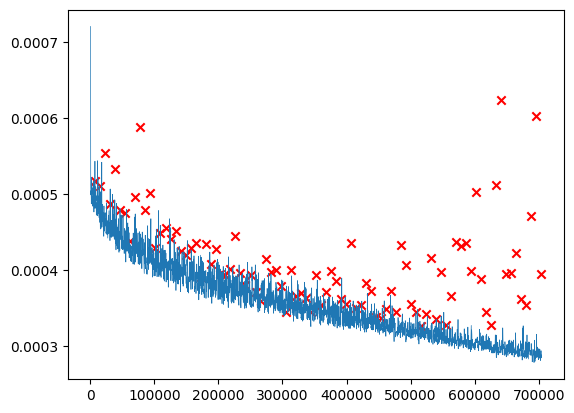

In [14]:
log = json.load(open('/home/trevor/repos/deep_TEE/tasks/experiments/test_s3d_224_32_1_0_3feature_nchamberfilter_test2/log.json', 'r'))
plt.plot(np.array(log['tick']), log['loss'], linewidth=0.5)
plt.scatter([log['tick'][i] for i,j in enumerate(log['valloss']) if not np.isnan(j)], [i for i in log['valloss'] if not np.isnan(i)], c='r', marker='x')
# plt.gca().set_yscale('log')

In [15]:
print(min([i for i in log['valloss'] if not np.isnan(i)]), np.where(np.array([i for i in log['valloss'] if not np.isnan(i)])==min([i for i in log['valloss'] if not np.isnan(i)])))

0.0003268092987127602 (array([65]),)


In [83]:
# model = torch.load('../experiments/test_s3d_224_32_1_0_3featuretest3/training-state-001252.pt')['net'].to(device).eval()
# model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/test_s3d_224_32_1_0_3feature_nchamberfilter_test1/*.pt'))[79])['net'].to(device)
# model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/test_s3d_224_32_1_0_3feature_nchamberfilter_test2/*.pt'))[65])['net'].to(device).eval()

# model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/test_s3d_224_32_1_0_3feature_nchamberfilter_test2/*.pt'))[65])['net'].to(device)
model = torch.load(sorted(glob.glob('/home/trevor/repos/deep_TEE/tasks/experiments/test_vit_128_32_1_0_3feature_nchamberfilter_test2/*.pt'))[100])['net'].to(device)

tensor([[nan, nan, nan]], device='cuda:1')
tensor([[0.6000, 0.0000, 0.4286]], dtype=torch.float64)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


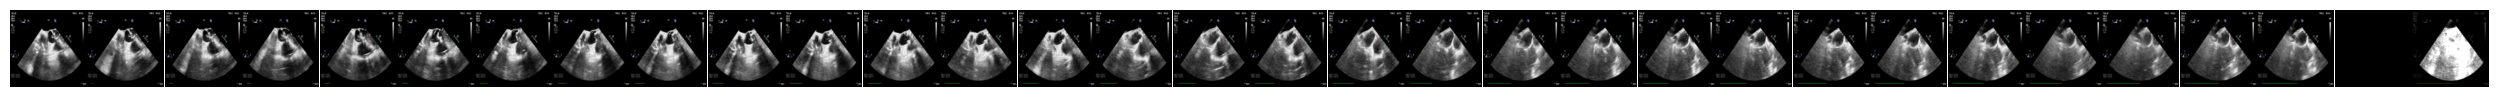

In [88]:
with torch.no_grad():
    # Visualize the images
    idx = np.random.randint(len(test_dataset))
    parcel = test_dataset[idx]['data']

    with torch.no_grad():
        print(model.eval()(test_dataset[idx]['data'].unsqueeze(0).to(device)))
        print(test_dataset[idx]['label'])

    fig, ax = plt.subplots(1,parcel.shape[1], figsize=(parcel.shape[1],1), frameon=False)
    for i in range(parcel.shape[1]):
        ax[i].imshow(parcel[:,i,:,:].permute(1,2,0))
        ax[i].set_axis_off()
    plt.subplots_adjust(wspace=0, hspace=0)

    # Accumulated motion image
    plt.imshow(torch.clamp(torch.sum(torch.abs(torch.diff(parcel,dim=1)), dim=1).permute(1,2,0) / parcel.shape[1] * 10, 0,255))

tensor([[0., 0., 0.]], device='cuda:1')
tensor([[0.1000, 1.0000, 0.8571]], dtype=torch.float64)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


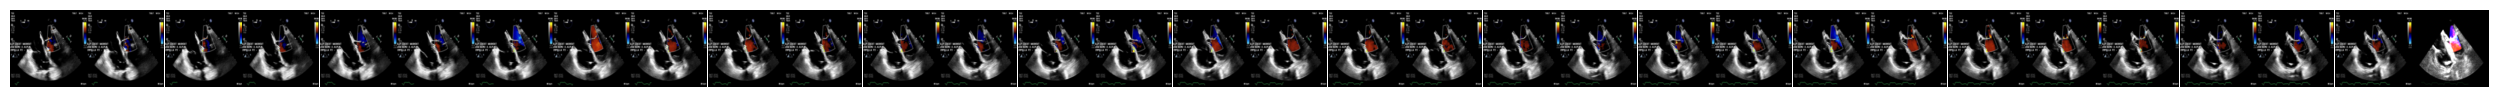

In [21]:
# Visualize the images
idx = np.random.randint(len(test_dataset))
parcel = test_dataset[idx]['data']

with torch.no_grad():
    print(model(test_dataset[idx]['data'].unsqueeze(0).to(device)))
    print(test_dataset[idx]['label'])

fig, ax = plt.subplots(1,parcel.shape[1], figsize=(parcel.shape[1],1), frameon=False)
for i in range(parcel.shape[1]):
    ax[i].imshow(parcel[:,i,:,:].permute(1,2,0))
    ax[i].set_axis_off()
plt.subplots_adjust(wspace=0, hspace=0)

# Accumulated motion image
plt.imshow(torch.clamp(torch.sum(torch.abs(torch.diff(parcel,dim=1)), dim=1).permute(1,2,0) / parcel.shape[1] * 10, 0,255))

## No Aggregation

In [22]:
y = []
yp = []
maxsample = 1000

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(test_dataset), maxsample))):
        # if test_dataset[idx]['label'] != test_dataset[idx]['label']:
        #     continue
        # if test_dataset[idx]['label'] > 1:
        #     continue
        y.append(test_dataset[idx]['label'].numpy().squeeze())
        yp.append(model(test_dataset[idx]['data'].unsqueeze(0).to(device)).cpu().numpy().squeeze())
       
results = np.concatenate((np.array(y),np.array(yp)), axis=1)
df = pd.DataFrame(results, columns=[f'{feature}_label' for feature in features] + [f'{feature}_pred' for feature in features])

  0%|          | 0/1000 [00:00<?, ?it/s]

100%|██████████| 1000/1000 [02:54<00:00,  5.74it/s]


/home/trevor/miniconda3/envs/view_classification/lib/python3.9/site-packages/scipy/stats/_stats_py.py:4781: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(msg))


Text(0.45, 0, "Pearson's r = nan")

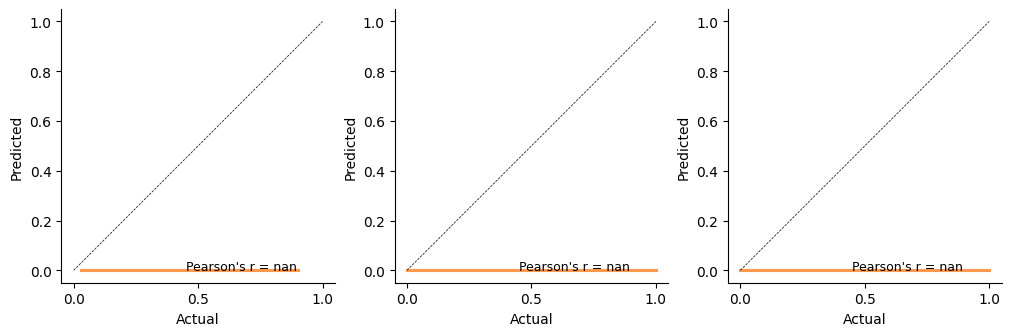

In [23]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

Text(0.45, 0, "Pearson's r = 0.64")

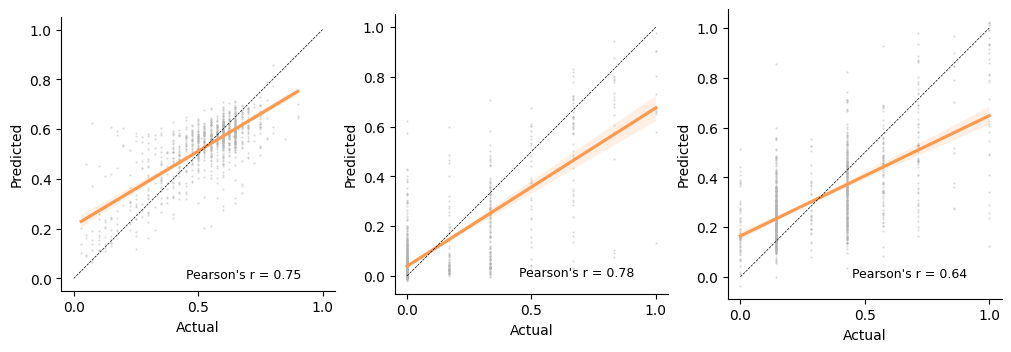

In [18]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

Text(0.45, 0, "Pearson's r = 0.43")

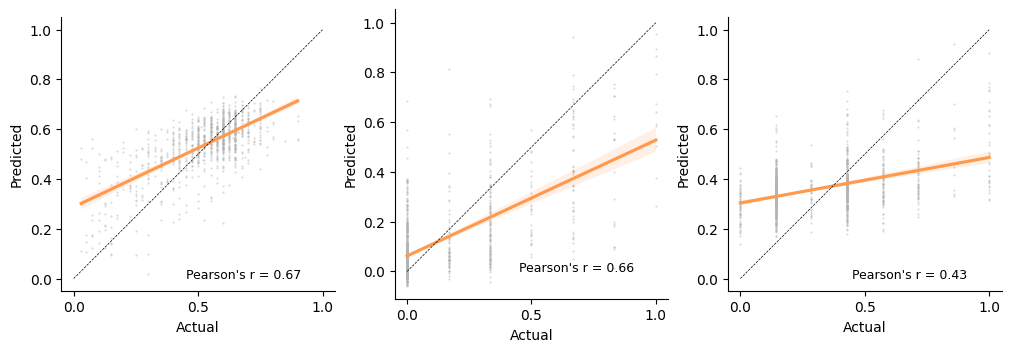

In [42]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

Text(0.45, 0, "Pearson's r = 0.27")

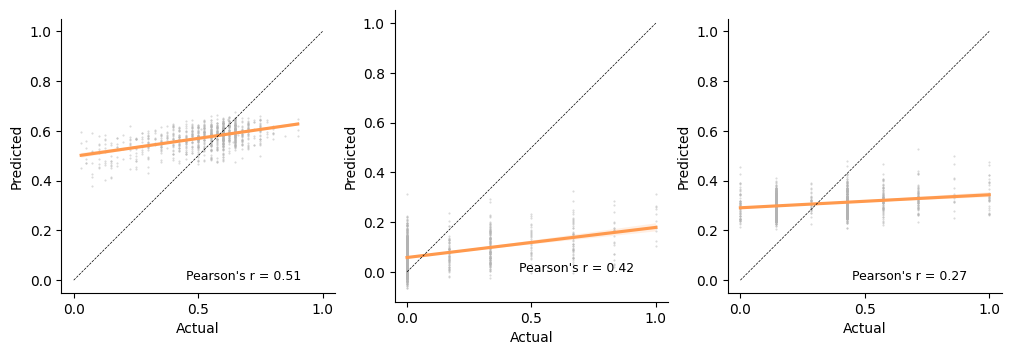

In [20]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

## Aggregation over a clip

In [19]:
class EvaluationDataset(torch.utils.data.Dataset):

    def __init__(self, clips, labels=None, transform=None, duration=32, skip=1, autobatch=True):
        self.clips = clips
        self.transform = transform
        self.duration = duration
        self.skip = skip
        self.autobatch = autobatch
        self.labels = labels

    def __len__(self):
        return len(self.clips)

    def __getitem__(self, idx):
        data = self.__read_images(self.clips[idx], self.duration, self.skip)
        
        if self.transform:
            data = self.transform(data)
            
        data = data.permute(0,2,1,3,4) # reshape to (B,C,T,H,W)
        
        if self.labels:
            label = labels[idx]
            return {'data':data, 'label':label}
        else:
            return {'data':data}
    
    def __read_images(self, path, duration=32, skip=1):
        frame_paths = glob.glob(path+'/*')
        if not self.autobatch:
            if len(frame_paths) <= duration * skip:
                start = 0
                stop = len(frame_paths)
                pad = (duration * skip - stop) // skip
            else:
                start = np.random.randint(0, len(frame_paths) - duration * skip + 1)
                stop = start + duration * skip
                pad = 0
            frames = []
            for frame in sorted(frame_paths)[start:stop:skip]:
                frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
            for i in range(pad):
                frames.append(torch.zeros_like(frames[-1]))
            frames = torch.stack(frames, dim=0)
            batches = frames
        else:
            batches = []
            for batch in range(int(np.ceil(len(frame_paths)/skip/duration))):
                start = batch * skip * duration
                stop = min((batch + 1) * skip * duration, len(frame_paths))
                pad = min(0, len(frame_paths) - ((batch + 1) * skip * duration))
                
                frames = []
                for frame in sorted(frame_paths)[start:stop:skip]:
                    frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
                for i in range(-pad//2):
                    frames.append(torch.zeros_like(frames[-1]))
                frames = torch.stack(frames, dim=0)
                batches.append(frames)
            batches = torch.stack(batches, dim=0)
        return batches

In [20]:
paths = [test_dataset.clip_paths[i] for i in range(len(test_dataset))]
labels = [test_dataset[i]['label'] for i in range(len(test_dataset))]

In [21]:
eval_dataset = EvaluationDataset(paths, labels=labels, transform=valtest_transforms, duration=32, skip=2, autobatch=True)

In [22]:
# y = []
# yp = []
# maxsample = 10000

# with torch.no_grad():
#     for idx in tqdm.tqdm(range(min(len(eval_dataset), maxsample))):
#         y.append(eval_dataset[idx]['label'])
#         yp.append(torch.mean(model(eval_dataset[idx]['data'].to(device))).item())
# df = pd.DataFrame({'y':y, 'yp':yp})

In [23]:
y = []
yp = []
maxsample = 10000

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(test_dataset), maxsample))):
        # if test_dataset[idx]['label'] != test_dataset[idx]['label']:
        #     continue
        # if test_dataset[idx]['label'] > 1:
        #     continue
        y.append(eval_dataset[idx]['label'].numpy().squeeze())
        # yp.append(model(eval_dataset[idx]['data'].unsqueeze(0).to(device)).cpu().numpy().squeeze())
        yp.append(model(eval_dataset[idx]['data'].to(device)).cpu().numpy().squeeze())
       
results = np.concatenate((np.array(y),np.array([np.mean(pred, axis=0) if len(pred.shape) == 2 else pred for pred in yp])), axis=1)

df = pd.DataFrame(results, columns=[f'{feature}_label' for feature in features] + [f'{feature}_pred' for feature in features])

df = df.drop(np.where(df['LVEF_label'] > 1)[0])

100%|██████████| 6099/6099 [06:07<00:00, 16.61it/s]


In [24]:
# fig, ax = plt.subplots(1,2, figsize=(6,3), layout="constrained")
# for a in ax:
#     a.spines[['right', 'top']].set_visible(False)
#     a.set_aspect('equal')
#     a.set_xticks([0,0.5,1])

# from scipy import stats
# res = stats.pearsonr(y, yp)
# sns.regplot(data=df, x="y", y="yp", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
# ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[0].set_aspect('equal')
# ax[0].set_ylabel('Predicted')
# ax[0].set_xlabel('Actual')
# ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


# y50 = [v > 0.5 for v in y]
# y25 = [v > 0.25 for v in y]

# testy, predy = y50, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

# testy, predy = y25, yp
# auc = roc_auc_score(testy, predy)
# print('Logistic: ROC AUC=%.3f' % (auc))
# fpr, tpr, _ = roc_curve(testy, predy)
# ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

# ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].legend(fontsize=8, frameon=False)
# ax[1].set_ylabel('True Positive Rate')
# ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')

Text(0.45, 0, "Pearson's r = 0.66")

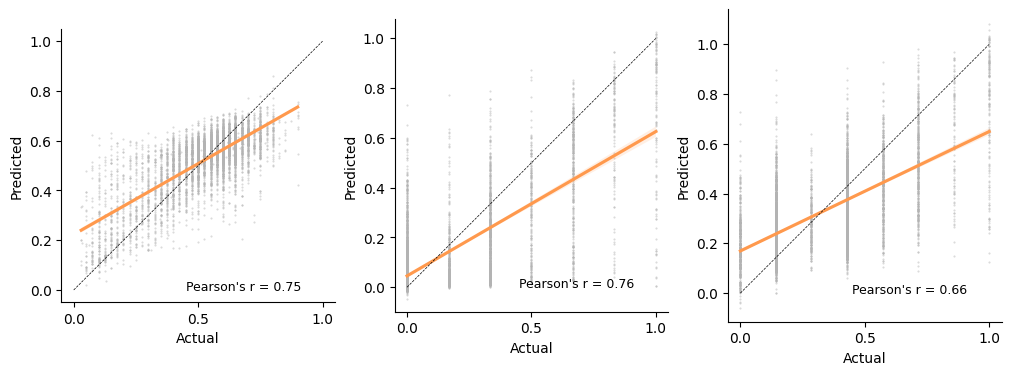

In [25]:
fig, ax = plt.subplots(1,3, figsize=(10,6), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)

## Aggregation over an entire study

In [26]:
# Aggregation over time for a study

y = []
yp = []
maxsample = 10000
running_pred = []
running_label = []
curr_acc = os.path.basename(os.path.split(eval_dataset.clips[0])[0])

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(eval_dataset), maxsample))):
        acc = os.path.basename(os.path.split(eval_dataset.clips[idx])[0])
        if acc != curr_acc:
            # print(running_label)
            # print(running_pred)
            y.append(running_label)
            yp.append(running_pred)
            running_pred = []
            running_label = []
            curr_acc = acc
            # print(running_label)
            # print(running_pred)
            # break
        
        running_pred.append(model(eval_dataset[idx]['data'].to(device)).cpu().numpy().squeeze())
        running_label.append(eval_dataset[idx]['label'].numpy().squeeze())
        # print(running_pred)
        # print(running_label)
        # break
        
ymean = []
ypmean = []
for i in range(len(yp)):
    ymean.append(np.mean(np.array(y[i]), axis=0))
    ypmean.append(np.mean(np.array(yp[i]), axis=0))

results = np.concatenate((np.array(ymean),np.array([np.mean(pred, axis=0) if len(pred.shape) == 2 else pred for pred in ypmean])), axis=1)
df = pd.DataFrame(results, columns=[f'{feature}_label' for feature in features] + [f'{feature}_pred' for feature in features])

df = df.drop(np.where(df['LVEF_label'] > 1)[0])

  0%|          | 3/6099 [00:00<04:29, 22.64it/s]

100%|██████████| 6099/6099 [05:52<00:00, 17.31it/s]


In [27]:
# # Aggregation over time for one study, broken into pre and post exam periods

# y_pre = []
# y_post = []
# yp_pre = []
# yp_post = []
# maxsample = 10000
# running_pred = []
# running_label = []
# curr_acc = os.path.basename(os.path.split(eval_dataset.clips[0])[0])
# curr_prepost = 0

# with torch.no_grad():
#     for idx in tqdm.tqdm(range(min(len(eval_dataset), maxsample))):
#         acc = os.path.basename(os.path.split(eval_dataset.clips[idx])[0])
#         prepost = eval_dataset[idx]['prepost']
#         if acc != curr_acc or prepost != curr_prepost:
#             y_pre.append(np.mean(running_label))
#             y_post.append(np.mean(running_label))
#             yp.append(np.mean(running_pred))
            
#             running_pred = []
#             running_label = []
#             curr_acc = acc
#             curr_prepost = prepost
        
#         running_pred.append(torch.mean(model(eval_dataset[idx]['data'].to(device))).item())
#         running_label.append(eval_dataset[idx]['label'])
        
# df = pd.DataFrame({'y':y, 'yp':yp})

Text(0.5, 1.0, 'TR')

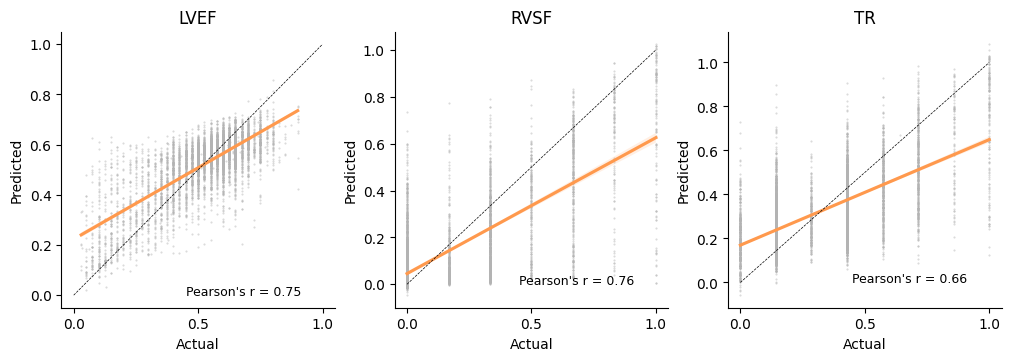

In [32]:
fig, ax = plt.subplots(1,3, figsize=(10,3.5), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    # a.set_aspect('equal')
    a.set_xticks([0,0.5,1])
    
lvefdf = df[['LVEF_label','LVEF_pred']].dropna()
rvsfdf = df[['RVSF_label','RVSF_pred']].dropna()
trdf = df[['TR_label','TR_pred']].dropna()

from scipy import stats
res = stats.pearsonr(lvefdf['LVEF_label'], lvefdf['LVEF_pred'])
sns.regplot(data=lvefdf, x="LVEF_label", y="LVEF_pred", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)
ax[0].set_title('LVEF')

res = stats.pearsonr(rvsfdf['RVSF_label'], rvsfdf['RVSF_pred'])
sns.regplot(data=rvsfdf, x="RVSF_label", y="RVSF_pred", marker='.', ax=ax[1], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[1].set_aspect('equal')
ax[1].set_ylabel('Predicted')
ax[1].set_xlabel('Actual')
ax[1].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)
ax[1].set_title('RVSF')

res = stats.pearsonr(trdf['TR_label'], trdf['TR_pred'])
sns.regplot(data=trdf, x="TR_label", y="TR_pred", marker='.', ax=ax[2], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[2].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
# ax[2].set_aspect('equal')
ax[2].set_ylabel('Predicted')
ax[2].set_xlabel('Actual')
ax[2].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)
ax[2].set_title('TR')